## Câu 1: Nhập dữ liệu Bank Marketing và thống kê các thông tin cơ bản của thuộc tính.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler

print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 1 (Trang 28)")

df = pd.read_csv("data/bank.csv", sep=";")

print("\nKích thước dữ liệu")
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])

print("\nNăm dòng dữ liệu đầu tiên")
print(df.head().to_string(index=False))

print("\nThông tin các thuộc tính")
df.info()

print("\nThống kê mô tả dữ liệu")
print(df.describe(include="all").T.to_string())

print("\nKết quả đăng ký gửi tiền")
so_luong_dang_ky = df["y"].value_counts()
ty_le_dang_ky = (df["y"].value_counts(normalize=True) * 100).round(2)
print(pd.DataFrame({"Số khách hàng": so_luong_dang_ky, "Tỷ lệ (%)": ty_le_dang_ky}).to_string())

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 1 (Trang 28)

Kích thước dữ liệu
Số dòng: 4521
Số cột: 17

Năm dòng dữ liệu đầu tiên
 age         job marital education default  balance housing loan  contact  day month  duration  campaign  pdays  previous poutcome  y
  30  unemployed married   primary      no     1787      no   no cellular   19   oct        79         1     -1         0  unknown no
  33    services married secondary      no     4789     yes  yes cellular   11   may       220         1    339         4  failure no
  35  management  single  tertiary      no     1350     yes   no cellular   16   apr       185         1    330         1  failure no
  30  management married  tertiary      no     1476     yes  yes  unknown    3   jun       199         4     -1         0  unknown no
  59 blue-collar married secondary      no        0     yes   no  unknown    5   may       226         1     -1         0  unknown no

Thông tin các thuộc tính
<class 'pandas.DataFrame'>


- Nhận xét: Dữ liệu có 4.521 khách hàng và 17 thuộc tính. Trong đó có 521 người đăng ký (11,52%) và 4.000 người không đăng ký (88,48%), cho thấy hai nhóm kết quả không cân bằng.

## Câu 2: Khảo sát kiểu dữ liệu, giá trị thiếu và các giá trị chưa xác định.

In [3]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 2 (Trang 28)")

thong_ke_cot = pd.DataFrame({
    "Kiểu dữ liệu": df.dtypes.astype(str),
    "Số giá trị khác nhau": df.nunique(),
    "Giá trị rỗng": df.isna().sum()
})

cot_dinh_tinh = df.select_dtypes(include=["object", "string"]).columns
thong_ke_cot["Giá trị unknown"] = 0
for cot in cot_dinh_tinh:
    thong_ke_cot.loc[cot, "Giá trị unknown"] = df[cot].eq("unknown").sum()

print("\nThống kê dữ liệu của từng thuộc tính")
print(thong_ke_cot.to_string())

print("\nNăm thuộc tính có nhiều giá trị unknown nhất")
print(thong_ke_cot["Giá trị unknown"].sort_values(ascending=False).head(5).to_string())

print("\nSố khách hàng chưa được liên hệ trong chiến dịch trước")
print((df["pdays"] == -1).sum())

print("\nSố dòng trùng hoàn toàn")
print(df.duplicated().sum())

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 2 (Trang 28)

Thống kê dữ liệu của từng thuộc tính
          Kiểu dữ liệu  Số giá trị khác nhau  Giá trị rỗng  Giá trị unknown
age              int64                    67             0                0
job                str                    12             0               38
marital            str                     3             0                0
education          str                     4             0              187
default            str                     2             0                0
balance          int64                  2353             0                0
housing            str                     2             0                0
loan               str                     2             0                0
contact            str                     3             0             1324
day              int64                    31             0                0
month              str                    12           

- Nhận xét: File không có giá trị `NaN`, nhưng các cột như `poutcome`, `contact`, `education` và `job` có nhãn `unknown`. Riêng `pdays = -1` có nghĩa là khách hàng chưa từng được liên hệ trong chiến dịch trước, không phải giá trị đo bị thiếu.

## Câu 3: Khảo sát mối liên hệ giữa độ tuổi, tình trạng hôn nhân và kết quả đăng ký gửi tiền.

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 3 (Trang 28)


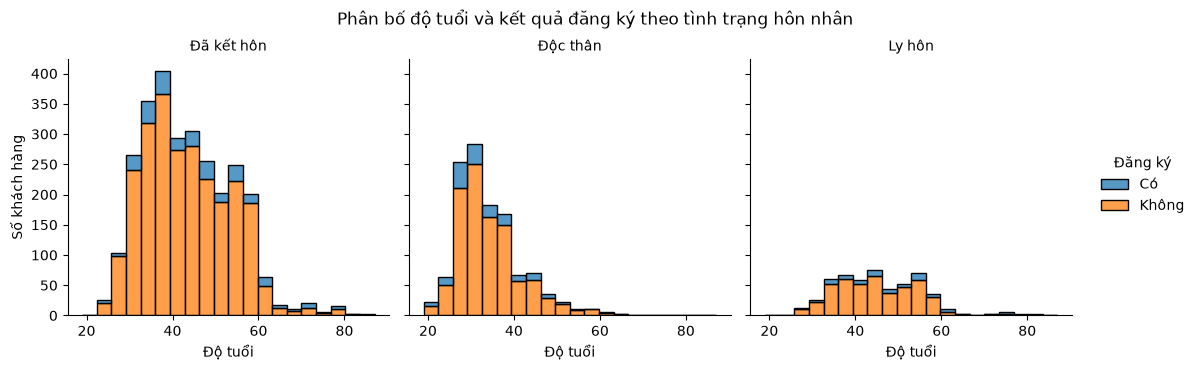


Số khách hàng và tỷ lệ đăng ký theo tình trạng hôn nhân (%)
            so_khach_hang  ty_le_dang_ky
Hôn nhân                                
Ly hôn                528          14.58
Đã kết hôn           2797           9.90
Độc thân             1196          13.96


In [4]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 3 (Trang 28)")

du_lieu_cau3 = df.copy()
du_lieu_cau3["Đăng ký"] = du_lieu_cau3["y"].map({"yes": "Có", "no": "Không"})
du_lieu_cau3["Hôn nhân"] = du_lieu_cau3["marital"].map({
    "married": "Đã kết hôn",
    "single": "Độc thân",
    "divorced": "Ly hôn"
})

bieu_do_cau3 = sns.displot(
    data=du_lieu_cau3,
    x="age",
    hue="Đăng ký",
    hue_order=["Có", "Không"],
    col="Hôn nhân",
    col_order=["Đã kết hôn", "Độc thân", "Ly hôn"],
    bins=20,
    multiple="stack",
    height=3.5,
    aspect=1.05
)
bieu_do_cau3.set_axis_labels("Độ tuổi", "Số khách hàng")
bieu_do_cau3.set_titles("{col_name}")
bieu_do_cau3.figure.suptitle(
    "Phân bố độ tuổi và kết quả đăng ký theo tình trạng hôn nhân", y=1.04
)
plt.show()

ty_le_hon_nhan = (
    du_lieu_cau3.assign(da_dang_ky=du_lieu_cau3["y"].eq("yes"))
    .groupby("Hôn nhân")["da_dang_ky"]
    .agg(so_khach_hang="count", ty_le_dang_ky="mean")
)
ty_le_hon_nhan["ty_le_dang_ky"] = (ty_le_hon_nhan["ty_le_dang_ky"] * 100).round(2)
print("\nSố khách hàng và tỷ lệ đăng ký theo tình trạng hôn nhân (%)")
print(ty_le_hon_nhan.to_string())

- Nhận xét: Khách hàng ly hôn (14,58%) và độc thân (13,96%) có tỷ lệ đăng ký cao hơn nhóm đã kết hôn (9,90%). Biểu đồ còn cho thấy số khách hàng và kết quả đăng ký khác nhau giữa các nhóm tuổi, nhưng không đủ để kết luận quan hệ nhân quả.

## Câu 4: Khảo sát sự liên quan giữa nghề nghiệp, trình độ học vấn, khoản vay và kết quả đăng ký.

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 4 (Trang 28)


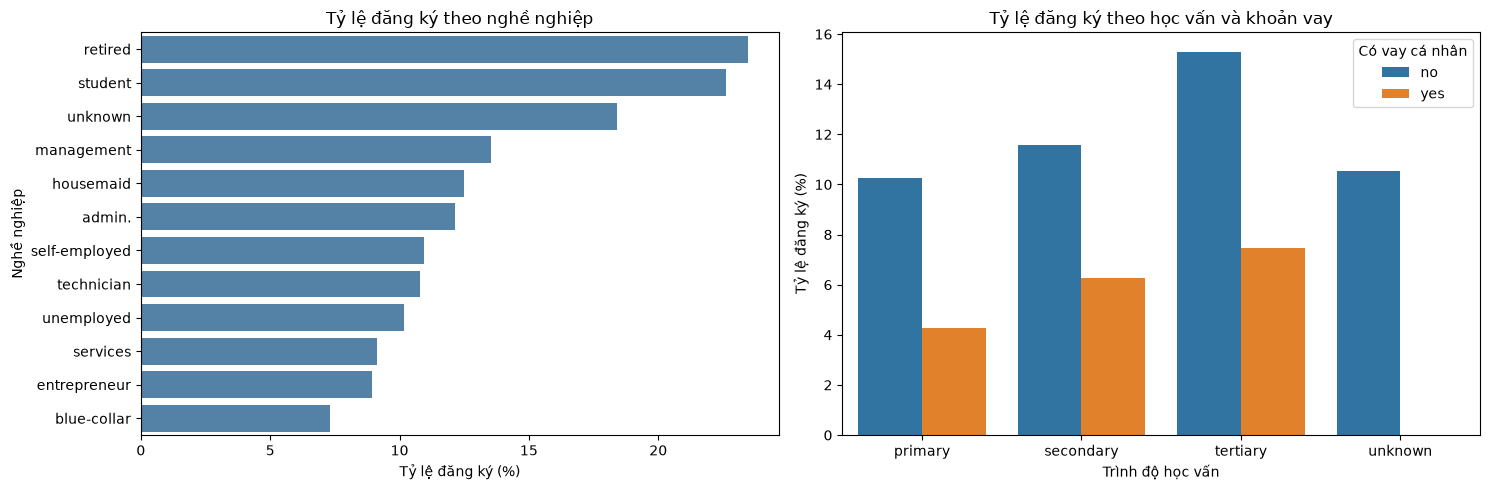


Thống kê theo nghề nghiệp
               so_khach_hang  ty_le_dang_ky
job                                        
retired                  230          23.48
student                   84          22.62
unknown                   38          18.42
management               969          13.52
housemaid                112          12.50
admin.                   478          12.13
self-employed            183          10.93
technician               768          10.81
unemployed               128          10.16
services                 417           9.11
entrepreneur             168           8.93
blue-collar              946           7.29

Tỷ lệ đăng ký theo tình trạng vay cá nhân (%)
loan
no     12.48
yes     6.22


In [5]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 4 (Trang 28)")

du_lieu_cau4 = df.copy()
du_lieu_cau4["da_dang_ky"] = du_lieu_cau4["y"].eq("yes").astype(int)

thong_ke_nghe = (
    du_lieu_cau4.groupby("job")["da_dang_ky"]
    .agg(so_khach_hang="count", ty_le_dang_ky="mean")
    .sort_values("ty_le_dang_ky", ascending=False)
)
thong_ke_nghe["ty_le_dang_ky"] *= 100

thong_ke_hoc_van = (
    du_lieu_cau4.groupby(["education", "loan"])["da_dang_ky"]
    .agg(so_khach_hang="count", ty_le_dang_ky="mean")
    .reset_index()
)
thong_ke_hoc_van["ty_le_dang_ky"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(
    x=thong_ke_nghe["ty_le_dang_ky"],
    y=thong_ke_nghe.index,
    color="steelblue",
    ax=axes[0]
)
axes[0].set_title("Tỷ lệ đăng ký theo nghề nghiệp")
axes[0].set_xlabel("Tỷ lệ đăng ký (%)")
axes[0].set_ylabel("Nghề nghiệp")

sns.barplot(
    data=thong_ke_hoc_van,
    x="education", y="ty_le_dang_ky", hue="loan",
    hue_order=["no", "yes"],
    ax=axes[1]
)
axes[1].set_title("Tỷ lệ đăng ký theo học vấn và khoản vay")
axes[1].set_xlabel("Trình độ học vấn")
axes[1].set_ylabel("Tỷ lệ đăng ký (%)")
axes[1].legend(title="Có vay cá nhân")

plt.tight_layout()
plt.show()

print("\nThống kê theo nghề nghiệp")
print(thong_ke_nghe.round(2).to_string())

print("\nTỷ lệ đăng ký theo tình trạng vay cá nhân (%)")
print((du_lieu_cau4.groupby("loan")["da_dang_ky"].mean() * 100).round(2).to_string())

- Nhận xét: Trong dữ liệu, nhóm nghỉ hưu và sinh viên có tỷ lệ đăng ký cao, còn nhóm lao động phổ thông thấp hơn. Người không có khoản vay cá nhân có tỷ lệ đăng ký 12,48%, cao hơn nhóm có vay (6,22%). Cần xét thêm quy mô từng nhóm khi so sánh.

## Câu 5: Khảo sát thời lượng cuộc gọi, số lần liên hệ và kết quả đăng ký gửi tiền.

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 5 (Trang 28)


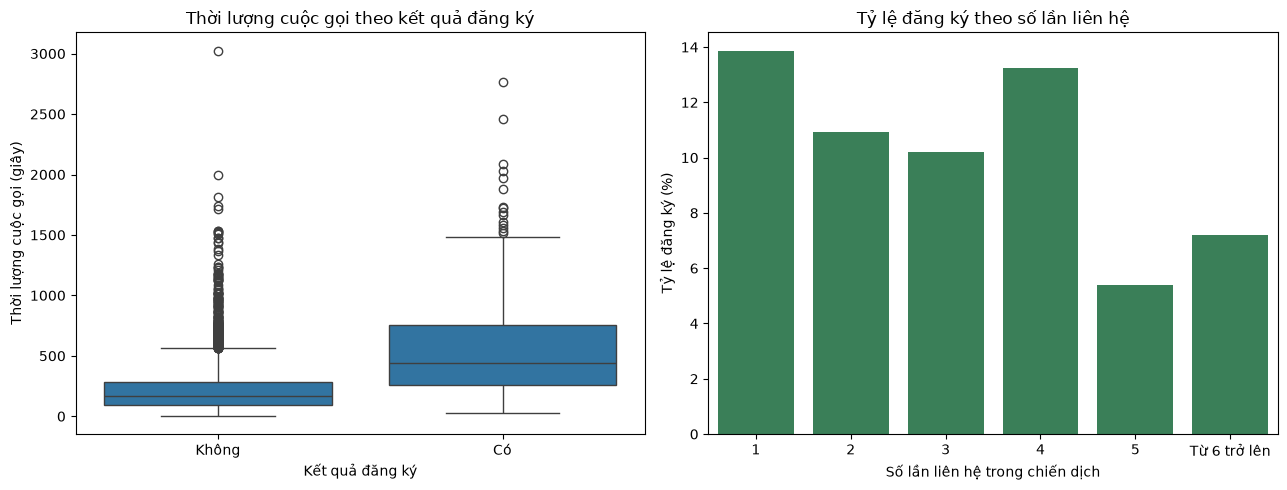


Thời lượng cuộc gọi theo kết quả đăng ký (giây)
         count    mean  median
Đăng ký                       
Có         521  552.74   442.0
Không     4000  226.35   167.0

Tỷ lệ đăng ký theo số lần liên hệ
                  so_khach_hang  ty_le_dang_ky
Nhóm lần liên hệ                              
1                          1734          13.84
2                          1264          10.92
3                           558          10.22
4                           325          13.23
5                           167           5.39
Từ 6 trở lên                473           7.19


In [6]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 5 (Trang 28)")

du_lieu_cau5 = df.copy()
du_lieu_cau5["Đăng ký"] = du_lieu_cau5["y"].map({"yes": "Có", "no": "Không"})
du_lieu_cau5["da_dang_ky"] = du_lieu_cau5["y"].eq("yes").astype(int)

du_lieu_cau5["Nhóm lần liên hệ"] = du_lieu_cau5["campaign"].apply(
    lambda n: str(n) if n <= 5 else "Từ 6 trở lên"
)
thu_tu_lien_he = ["1", "2", "3", "4", "5", "Từ 6 trở lên"]

thong_ke_lien_he = (
    du_lieu_cau5.groupby("Nhóm lần liên hệ")["da_dang_ky"]
    .agg(so_khach_hang="count", ty_le_dang_ky="mean")
    .reindex(thu_tu_lien_he)
)
thong_ke_lien_he["ty_le_dang_ky"] *= 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(
    data=du_lieu_cau5,
    x="Đăng ký", y="duration", order=["Không", "Có"],
    ax=axes[0]
)
axes[0].set_title("Thời lượng cuộc gọi theo kết quả đăng ký")
axes[0].set_xlabel("Kết quả đăng ký")
axes[0].set_ylabel("Thời lượng cuộc gọi (giây)")

sns.barplot(
    x=thong_ke_lien_he.index,
    y=thong_ke_lien_he["ty_le_dang_ky"],
    color="seagreen", ax=axes[1]
)
axes[1].set_title("Tỷ lệ đăng ký theo số lần liên hệ")
axes[1].set_xlabel("Số lần liên hệ trong chiến dịch")
axes[1].set_ylabel("Tỷ lệ đăng ký (%)")

plt.tight_layout()
plt.show()

print("\nThời lượng cuộc gọi theo kết quả đăng ký (giây)")
print(du_lieu_cau5.groupby("Đăng ký")["duration"].agg(["count", "mean", "median"]).round(2).to_string())

print("\nTỷ lệ đăng ký theo số lần liên hệ")
print(thong_ke_lien_he.round(2).to_string())

- Nhận xét: Cuộc gọi của nhóm đăng ký thành công có thời lượng trung vị 442 giây, lớn hơn nhóm không đăng ký (167 giây). Tỷ lệ đăng ký cũng thay đổi theo số lần liên hệ. Thời lượng cuộc gọi chỉ biết sau khi liên hệ, nên không nên dùng để dự đoán trước cuộc gọi.

## Câu 6: Tiền xử lý dữ liệu chưa xác định, mã hóa thuộc tính định tính và chuẩn hóa thuộc tính số.

In [7]:
print("Họ và tên: Lê Công Tài")
print("MSSV: 6451071067")
print("Lab 1, Bài 2, Câu 6 (Trang 28)")

du_lieu_cau6 = df.copy()

print("\nSố lượng giá trị rỗng ban đầu")
print(du_lieu_cau6.isna().sum().to_string())

du_lieu_cau6["da_lien_he_truoc"] = (du_lieu_cau6["pdays"] != -1).astype(int)
du_lieu_cau6["pdays"] = du_lieu_cau6["pdays"].replace(-1, 0)

for cot in ["job", "education", "contact"]:
    du_lieu_cau6[cot] = du_lieu_cau6[cot].replace("unknown", np.nan)

cot_so = du_lieu_cau6.select_dtypes(include="number").columns.drop("da_lien_he_truoc")
for cot in cot_so:
    du_lieu_cau6[cot] = du_lieu_cau6[cot].fillna(du_lieu_cau6[cot].median())

cot_chu = du_lieu_cau6.select_dtypes(include=["object", "string"]).columns.drop("y")
for cot in cot_chu:
    du_lieu_cau6[cot] = du_lieu_cau6[cot].fillna(du_lieu_cau6[cot].mode()[0])

print("\nSố lượng giá trị rỗng sau khi xử lý")
print(du_lieu_cau6.isna().sum().to_string())

du_lieu_cau6["y"] = du_lieu_cau6["y"].map({"no": 0, "yes": 1})

du_lieu_ma_hoa = pd.get_dummies(du_lieu_cau6, columns=list(cot_chu), dtype=int)

cot_chuan_hoa = [
    "age", "balance", "day", "duration",
    "campaign", "pdays", "previous"
]
bo_chuan_hoa = MinMaxScaler()
du_lieu_ma_hoa[cot_chuan_hoa] = bo_chuan_hoa.fit_transform(
    du_lieu_ma_hoa[cot_chuan_hoa]
)

print("\nKích thước dữ liệu sau khi mã hóa")
print("Số dòng:", du_lieu_ma_hoa.shape[0])
print("Số cột:", du_lieu_ma_hoa.shape[1])
print("Tổng số giá trị rỗng:", du_lieu_ma_hoa.isna().sum().sum())

print("\nNăm dòng dữ liệu sau tiền xử lý (12 cột đầu)")
print(du_lieu_ma_hoa.iloc[:5, :12].to_string(index=False))

du_lieu_ma_hoa.to_csv("data/bank_da_tien_xu_ly.csv", index=False)
print("\nĐã lưu dữ liệu tiền xử lý vào data/bank_da_tien_xu_ly.csv")

Họ và tên: Lê Công Tài
MSSV: 6451071067
Lab 1, Bài 2, Câu 6 (Trang 28)

Số lượng giá trị rỗng ban đầu
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0

Số lượng giá trị rỗng sau khi xử lý
age                 0
job                 0
marital             0
education           0
default             0
balance             0
housing             0
loan                0
contact             0
day                 0
month               0
duration            0
campaign            0
pdays               0
previous            0
poutcome            0
y                   0
da_lien_he_truoc    0

Kích thước dữ liệu sau khi mã hóa
Số dòng: 4521
Số cột: 50
Tổng số giá trị rỗng: 0

Năm dòng dữ liệu sau tiền xử lý (12 cột đầu)
     age  balance      day  duration  campaign    pdays  previous  y  da_lien_he

- Nhận xét: Các giá trị `unknown` ở `job`, `education`, `contact` được thay bằng giá trị xuất hiện nhiều nhất; `poutcome = unknown` được giữ như một nhóm riêng. `pdays = -1` được xử lý có lưu cờ liên hệ trước. Dữ liệu được mã hóa One-hot và chuẩn hóa Min-max, không còn ô trống.